<a href="https://colab.research.google.com/github/Gujardg/DataSet_Preparation_Activity1/blob/main/Program1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("First 5 records:")
display(df.head())

print("Last 5 records:")
display(df.tail())

print("Number of rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

First 5 records:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Last 5 records:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


Number of rows and columns: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [ ]:
numerical_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(include="object").columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

print("\nNumerical summary:")
display(df.describe())

print("\nCategorical summary:")
display(df.describe(include="object"))

Numerical columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']

Numerical summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Categorical summary:


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


In [ ]:
missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing_report)

,Missing Values,Missing Percentage
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


In [ ]:
# Keep the original dataset unchanged
data = df.copy()

# Remove columns not used in this basic preparation activity:
# PassengerId is an identifier; Name and Ticket are text identifiers;
# Cabin has a large amount of missing data.
data = data.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

# Fill numerical missing values with the median
data["Age"] = data["Age"].fillna(data["Age"].median())
data["Fare"] = data["Fare"].fillna(data["Fare"].median())

# Fill categorical missing values with the most common category (mode)
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

print("Missing values after handling:")
display(data.isnull().sum())

Missing values after handling:


,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


In [ ]:
print("Duplicate rows before removal:", data.duplicated().sum())

# Remove exact duplicate rows, if any
data = data.drop_duplicates().copy()

# Standardize text formatting
data["Sex"] = data["Sex"].str.strip().str.lower()
data["Embarked"] = data["Embarked"].str.strip().str.upper()

print("Duplicate rows after removal:", data.duplicated().sum())
print("Sex categories:", data["Sex"].unique())
print("Embarked categories:", data["Embarked"].unique())

display(data.head())

Duplicate rows before removal: 116
Duplicate rows after removal: 0
Sex categories: ['male' 'female']
Embarked categories: ['S' 'C' 'Q']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [ ]:
print("Summary statistics:")
display(data.describe())

print("Passenger counts by sex:")
display(data["Sex"].value_counts())

print("Passenger counts by port:")
display(data["Embarked"].value_counts())

Summary statistics:


,Survived,Pclass,Age,SibSp,Parch,Fare
count,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,0.412903,2.246452,29.581187,0.529032,0.420645,34.878403
std,0.492674,0.853574,13.766359,0.990326,0.840565,52.408474
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,15.900000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.197900
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Passenger counts by sex:


,count
Sex,
male,483
female,292


Passenger counts by port:


,count
Embarked,
S,562
C,155
Q,58


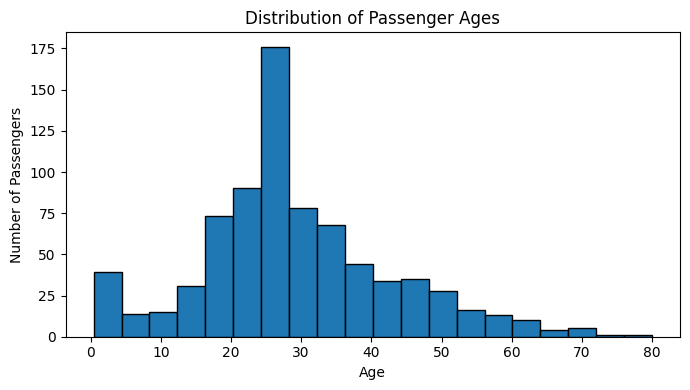

In [ ]:
# Histogram: passenger age distribution
plt.figure(figsize=(7, 4))
plt.hist(data["Age"], bins=20, edgecolor="black")
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

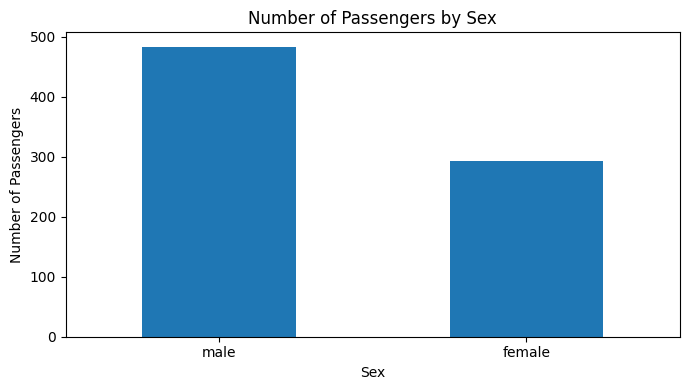

In [ ]:
# Bar chart: passenger counts by sex
plt.figure(figsize=(7, 4))
data["Sex"].value_counts().plot(kind="bar")
plt.title("Number of Passengers by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

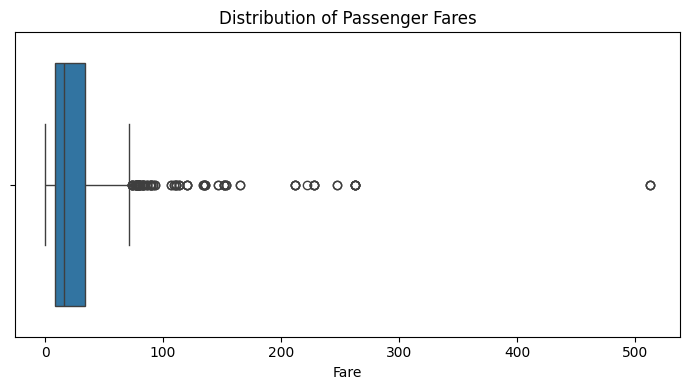

In [ ]:
# Box plot: ticket fare distribution
plt.figure(figsize=(7, 4))
sns.boxplot(x=data["Fare"])
plt.title("Distribution of Passenger Fares")
plt.xlabel("Fare")
plt.tight_layout()
plt.show()

In [ ]:
# One-hot encode nominal categories.
# Pclass is treated as a category here because it represents passenger classes.
data_encoded = pd.get_dummies(
    data,
    columns=["Sex", "Embarked", "Pclass"],
    dtype=int
)

print("Dataset after one-hot encoding:")
display(data_encoded.head())

print("Columns after encoding:")
print(data_encoded.columns.tolist())

Dataset after one-hot encoding:


,Survived,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,0,22.0,1,0,7.2500,0,1,0,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0,1,0,0
2,1,26.0,0,0,7.9250,1,0,0,0,1,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1,1,0,0
4,0,35.0,0,0,8.0500,0,1,0,0,1,0,0,1


Columns after encoding:
['Survived', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Pclass_1', 'Pclass_2', 'Pclass_3']


In [ ]:
# Standardize selected numerical input features.
# Do not scale the possible target column 'Survived' or identifiers.
scale_columns = ["Age", "SibSp", "Parch", "Fare"]

scaler = StandardScaler()
data_encoded[scale_columns] = scaler.fit_transform(data_encoded[scale_columns])

print("Dataset after scaling:")
display(data_encoded.head())

print("Scaled column means (approximately 0):")
print(data_encoded[scale_columns].mean().round(2))

print("\nScaled column standard deviations (approximately 1):")
print(data_encoded[scale_columns].std().round(2))

Dataset after scaling:


,Survived,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,0,-0.551060,0.475876,-0.500754,-0.527515,0,1,0,0,1,0,0,1
1,1,0.611945,0.475876,-0.500754,0.695086,1,0,1,0,0,1,0,0
2,1,-0.260308,-0.534545,-0.500754,-0.514627,1,0,0,0,1,0,0,1
3,1,0.393881,0.475876,-0.500754,0.347909,1,0,0,0,1,1,0,0
4,0,0.393881,-0.534545,-0.500754,-0.512240,0,1,0,0,1,0,0,1


Scaled column means (approximately 0):
Age      0.0
SibSp   -0.0
Parch    0.0
Fare    -0.0
dtype: float64

Scaled column standard deviations (approximately 1):
Age      1.0
SibSp    1.0
Parch    1.0
Fare     1.0
dtype: float64


In [ ]:
print("Final dataset shape:", data_encoded.shape)
print("Remaining missing values:", data_encoded.isnull().sum().sum())
print("Remaining duplicate rows:", data_encoded.duplicated().sum())

print("\nSample of final prepared data:")
display(data_encoded.head(10))

output_file = "Prepared_Titanic.csv"
data_encoded.to_csv(output_file, index=False)
print(f"Dataset saved as {output_file}")

Final dataset shape: (775, 13)
Remaining missing values: 0
Remaining duplicate rows: 0

Sample of final prepared data:


,Survived,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,0,-0.551060,0.475876,-0.500754,-0.527515,0,1,0,0,1,0,0,1
1,1,0.611945,0.475876,-0.500754,0.695086,1,0,1,0,0,1,0,0
2,1,-0.260308,-0.534545,-0.500754,-0.514627,1,0,0,0,1,0,0,1
3,1,0.393881,0.475876,-0.500754,0.347909,1,0,0,0,1,1,0,0
4,0,0.393881,-0.534545,-0.500754,-0.512240,0,1,0,0,1,0,0,1
5,0,-0.114933,-0.534545,-0.500754,-0.504444,0,1,0,1,0,0,0,1
6,0,1.774949,-0.534545,-0.500754,0.324281,0,1,0,0,1,1,0,0
7,0,-2.004815,2.496717,0.689689,-0.263551,0,1,0,0,1,0,0,1
8,1,-0.187621,-0.534545,1.880133,-0.453370,1,0,0,0,1,0,0,1
9,1,-1.132562,0.475876,-0.500754,-0.091793,1,0,1,0,0,0,1,0


Dataset saved as Prepared_Titanic.csv


In [ ]:
# Google Colab download (skip this cell if using local Jupyter)
from google.colab import files
files.download("Prepared_Titanic.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>